# Mudeng · Dengue: what the genomes show
**Question:** How similar are the four dengue serotypes in their Envelope (E) protein, which parts are conserved, and how much Indonesian sequence data is publicly available?

Everything here uses public NCBI data. Output files (CSV, figures, provenance) are saved for the website and GitHub. **Educational analysis, not medical advice.**

Run the cells top to bottom. Edit your email in the next cell (NCBI requires it).

In [7]:
!pip -q install biopython
!apt-get -qq install -y mafft > /dev/null
import io, re, json, time, subprocess, datetime, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import Bio
from Bio import Entrez, SeqIO, Phylo
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Align import MultipleSeqAlignment
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor

Entrez.email = "elhannanliafwirrahman@gmail.com"   # <- put your real email
os.makedirs("outputs", exist_ok=True)
RETRIEVED = datetime.date.today().isoformat()

## 1. Reference genomes and the Envelope protein
We take the NCBI RefSeq genome of each serotype and cut out the annotated Envelope protein.

In [8]:
REFS = {"DENV-1":"NC_001477", "DENV-2":"NC_001474", "DENV-3":"NC_001475", "DENV-4":"NC_002640"}

def fetch_gb(acc):
    h = Entrez.efetch(db="nuccore", id=acc, rettype="gb", retmode="text")
    rec = SeqIO.read(h, "genbank"); h.close(); time.sleep(0.4)
    return rec

E_prot, rows = {}, []
for name, acc in REFS.items():
    rec = fetch_gb(acc)
    if f"dengue virus {name[-1]}" not in rec.description.lower():
        print("WARNING: check this record, title does not match:", acc, rec.description)
    feats = [f for f in rec.features if f.type == "mat_peptide"
             and "envelope" in " ".join(f.qualifiers.get("product", [])).lower()]
    if not feats:
        print("No envelope feature found. Products:", [f.qualifiers.get("product") for f in rec.features if f.type == "mat_peptide"])
        raise SystemExit
    nt = feats[0].extract(rec.seq)
    aa = str(nt.translate()).rstrip("*")
    E_prot[name] = aa
    rows.append((name, rec.id, rec.description, len(nt), len(aa)))
refs_df = pd.DataFrame(rows, columns=["serotype", "accession", "title", "E_nt", "E_aa"])
refs_df.to_csv("outputs/reference_genomes.csv", index=False)
refs_df

,serotype,accession,title,E_nt,E_aa
0,DENV-1,NC_001477.1,"Dengue virus 1, complete genome",1485,495
1,DENV-2,NC_001474.2,"Dengue virus 2, complete genome",1485,495
2,DENV-3,NC_001475.2,"Dengue virus 3, complete genome",1479,493
3,DENV-4,NC_002640.1,"Dengue virus 4, complete genome",1485,495


**Check this table:** each E protein should be about 495 amino acids. If a title or length looks wrong, stop and fix before continuing.

## 2. Multiple sequence alignment and similarity

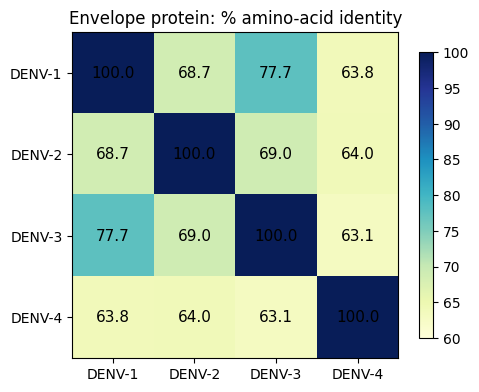

,DENV-1,DENV-2,DENV-3,DENV-4
DENV-1,100.0,68.7,77.7,63.8
DENV-2,68.7,100.0,69.0,64.0
DENV-3,77.7,69.0,100.0,63.1
DENV-4,63.8,64.0,63.1,100.0


In [9]:
def run_mafft(seqs):
    with open("/tmp/in.fa", "w") as f:
        for k, v in seqs.items(): f.write(f">{k}\n{v}\n")
    out = subprocess.run(["mafft", "--auto", "--quiet", "/tmp/in.fa"], capture_output=True, text=True, check=True).stdout
    return {r.id: str(r.seq).upper() for r in SeqIO.parse(io.StringIO(out), "fasta")}

aln = run_mafft(E_prot)
names = list(E_prot)

def identity(a, b):
    pairs = [(x, y) for x, y in zip(a, b) if x != "-" and y != "-"]
    return 100 * sum(x == y for x, y in pairs) / len(pairs)

M = pd.DataFrame([[identity(aln[i], aln[j]) for j in names] for i in names], index=names, columns=names).round(1)
M.to_csv("outputs/identity_matrix.csv")

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(M.values, cmap="YlGnBu", vmin=60, vmax=100)
ax.set_xticks(range(4)); ax.set_xticklabels(names); ax.set_yticks(range(4)); ax.set_yticklabels(names)
for i in range(4):
    for j in range(4): ax.text(j, i, M.values[i, j], ha="center", va="center", fontsize=11)
ax.set_title("Envelope protein: % amino-acid identity")
plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.savefig("outputs/identity_heatmap.png", dpi=200); plt.show()
M

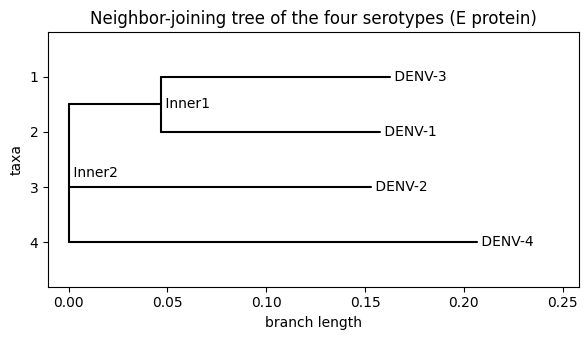

In [10]:
msa = MultipleSeqAlignment([SeqRecord(Seq(aln[n]), id=n) for n in names])
dm = DistanceCalculator("identity").get_distance(msa)
tree = DistanceTreeConstructor().nj(dm)
fig = plt.figure(figsize=(6, 3.5)); ax = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, axes=ax, do_show=False)
ax.set_title("Neighbor-joining tree of the four serotypes (E protein)")
plt.tight_layout(); plt.savefig("outputs/serotype_tree.png", dpi=200); plt.show()

## 3. Which parts of the Envelope protein are conserved?
Positions are numbered along DENV-2 E. Domain boundaries below follow the commonly cited DENV-2 E structure (Modis et al., 2003). **Verify them against the paper before publishing.**

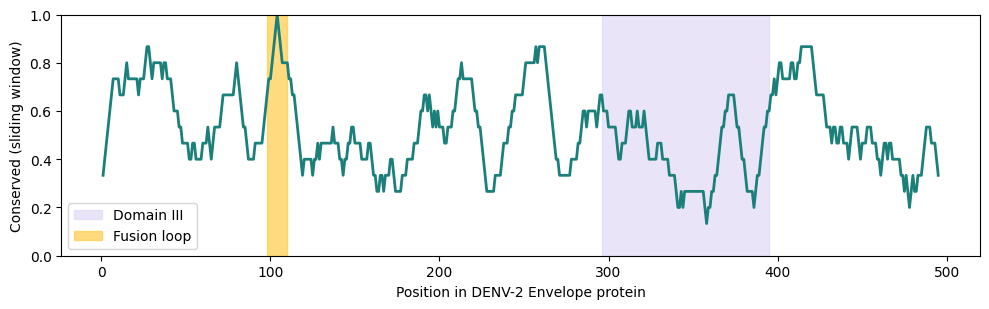

,region,residues,% identical in all 4 serotypes
0,Domain I,128,54.7
1,Domain II,167,56.3
2,Domain III,100,42.0
3,Fusion loop,13,100.0


In [11]:
ref = "DENV-2"
L = len(aln[ref])
cons = np.array([len({aln[n][i] for n in names}) == 1 and aln[ref][i] != "-" for i in range(L)])
pos, k = [], 0
for i in range(L):
    if aln[ref][i] != "-": k += 1; pos.append(k)
    else: pos.append(None)
pos = np.array([p if p else np.nan for p in pos], dtype=float)

DOMAINS = {"Domain I": [(1,51),(132,192),(280,295)], "Domain II": [(52,131),(193,279)],
           "Domain III": [(296,395)], "Fusion loop": [(98,110)]}
res = []
for d, spans in DOMAINS.items():
    m = np.zeros(L, bool)
    for a, b in spans: m |= (pos >= a) & (pos <= b)
    res.append((d, int(m.sum()), round(100 * cons[m].mean(), 1)))
dom_df = pd.DataFrame(res, columns=["region", "residues", "% identical in all 4 serotypes"])
dom_df.to_csv("outputs/conservation_by_domain.csv", index=False)

valid = ~np.isnan(pos)
win = 15
smooth = np.convolve(cons[valid].astype(float), np.ones(win) / win, mode="same")
fig, ax = plt.subplots(figsize=(10, 3.2))
for (a, b) in DOMAINS["Domain III"]: ax.axvspan(a, b, color="#DCD3F5", alpha=.6, label="Domain III")
for (a, b) in DOMAINS["Fusion loop"]: ax.axvspan(a, b, color="#FFCB47", alpha=.7, label="Fusion loop")
ax.plot(pos[valid], smooth, color="#1B7F7A", lw=2)
ax.set_xlabel("Position in DENV-2 Envelope protein"); ax.set_ylabel("Conserved (sliding window)")
ax.set_ylim(0, 1); ax.legend(loc="lower left"); plt.tight_layout()
plt.savefig("outputs/conservation_profile.png", dpi=200); plt.show()
dom_df

**Interpretation guide (write your own words after seeing the numbers):** compare the fusion loop with Domain III. Say only what the table shows. Sequence similarity across four reference genomes does **not** show protection, severity or vaccine performance.

## 4. How much Indonesian dengue sequence data is public?
This counts GenBank records that mention Indonesia, by serotype and year. It is a census of what exists, not the true prevalence.

In [23]:
def get_docs(s):
    # Bio.Entrez.Parser.ListElement inherits from list; check this first to avoid dictionary key TypeErrors
    if isinstance(s, list):
        return s
    if isinstance(s, dict):
        if "result" in s:
            res = s["result"]
            uids = res.get("uids", [])
            return [res[uid] for uid in uids if uid in res]
        if "DocumentSummarySet" in s:
            return list(s["DocumentSummarySet"]["DocumentSummary"])
        if "uids" in s:
            return [s[u] for u in s["uids"] if u in s]
    raise RuntimeError(f"Unexpected esummary structure, type: {type(s)}")

def parse_tags(d):
    st = str(d.get("SubType", "") or "").split("|")
    sn = str(d.get("SubName", "") or "").split("|")
    return dict(zip(st, sn)) if st != [""] and len(st) == len(sn) else {}

def gb_tags(accs):
    h = Entrez.efetch(db="nuccore", id=",".join(accs), rettype="gb", retmode="text")
    out = {}
    for rec in SeqIO.parse(h, "genbank"):
        src = next((f for f in rec.features if f.type == "source"), None)
        q = src.qualifiers if src else {}
        out[rec.id] = {"country": q.get("country", [""])[0],
                       "collection_date": q.get("collection_date", [""])[0]}
    h.close(); time.sleep(0.4)
    return out

def census(sero_name):
    q = f'"{sero_name}"[Organism] AND Indonesia[All Fields]'
    h = Entrez.esearch(db="nuccore", term=q, retmax=1000); r = Entrez.read(h); h.close()
    ids = r["IdList"]; out = []
    print(sero_name, "- search hits:", len(ids))
    for i in range(0, len(ids), 100):
        batch = ids[i:i+100]
        h = Entrez.esummary(db="nuccore", id=",".join(batch), version="2.0")
        s = Entrez.read(h); h.close(); time.sleep(0.4)
        docs = get_docs(s)
        if len(docs) == 0:
            raise RuntimeError("esummary returned 0 documents for a non-empty id list")
        missing = []
        for d in docs:
            tags = parse_tags(d)
            rec = {"accession": str(d.get("AccessionVersion", "")),
                   "title": str(d.get("Title", "")),
                   "length": int(d.get("Slen", 0) or 0),
                   "country": tags.get("country", ""),
                   "collection_date": tags.get("collection_date", "")}
            if not rec["country"]:
                missing.append(rec)
            out.append(rec)
        if missing:
            try:
                extra = gb_tags([m["accession"] for m in missing])
                for m in missing: m.update(extra.get(m["accession"], {}))
            except Exception as e:
                print("GenBank fallback failed:", e)
    return out

allrows = []
for sero in ["DENV-1", "DENV-2", "DENV-3", "DENV-4"]:
    for rrow in census(f"Dengue virus {sero[-1]}"):
        rrow["serotype"] = sero; allrows.append(rrow)
cdf = pd.DataFrame(allrows, columns=["accession","title","length","country","collection_date","serotype"])
print("Records returned by search:", len(cdf))
cdf = cdf[cdf["country"].astype(str).str.contains("Indonesia", case=False, na=False)].copy()
if cdf.empty:
    print("WARNING: no record with country=Indonesia found. Do NOT report 'no data' until this is debugged.")
cdf["year"] = cdf["collection_date"].astype(str).str.extract(r"((?:19|20)\d{2})")[0].astype(float)
def kind(n):
    return "complete genome-sized (>10 kb)" if n > 10000 else ("E-gene-sized (1.4-1.6 kb)" if 1400 <= n <= 1600 else "other fragment")
cdf["kind"] = cdf["length"].apply(kind)
cdf.to_csv("outputs/indonesia_census.csv", index=False)

print("Indonesian records with country field:", len(cdf), "| with a collection year:", int(cdf["year"].notna().sum()))
if not cdf.empty:
    print(cdf.groupby("serotype").size().to_string())
    print(pd.crosstab(cdf["serotype"], cdf["kind"]).to_string())

piv = cdf.dropna(subset=["year"]).pivot_table(index="year", columns="serotype", values="accession", aggfunc="count").fillna(0)
if len(piv):
    piv.plot(kind="bar", stacked=True, figsize=(10, 3.5), width=.85, colormap="viridis")
    plt.ylabel("Public sequences"); plt.title("Indonesian dengue sequences in GenBank, by collection year")
    plt.tight_layout(); plt.savefig("outputs/indonesia_census_by_year.png", dpi=200); plt.show()

Dengue virus 1 - search hits: 674


TypeError: list indices must be integers or slices, not str

## 5. Save provenance (this is what makes it reproducible)

In [17]:
mafft_v = subprocess.run(["mafft", "--version"], capture_output=True, text=True).stderr.strip()
prov = {"retrieved": RETRIEVED, "biopython": Bio.__version__, "mafft": mafft_v,
        "references": REFS, "indonesia_records_with_country_field": int(len(cdf)),
        "note": "Counts reflect what is public in GenBank on the retrieval date, not true prevalence."}
json.dump(prov, open("outputs/provenance.json", "w"), indent=2)
!zip -qr mudeng_dengue_outputs.zip outputs
print(json.dumps(prov, indent=2))
try:
    from google.colab import files; files.download("mudeng_dengue_outputs.zip")
except Exception as e:
    print("Download the zip from the Colab file panel.")

{
  "retrieved": "2026-11-11",
  "biopython": "1.88",
  "mafft": "v7.505 (2022/Apr/10)",
  "references": {
    "DENV-1": "NC_001477",
    "DENV-2": "NC_001474",
    "DENV-3": "NC_001475",
    "DENV-4": "NC_002640"
  },
  "indonesia_records_with_country_field": 0,
  "note": "Counts reflect what is public in GenBank on the retrieval date, not true prevalence."
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>